# **Import libraries**

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import chi2
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, mean_absolute_error, mean_squared_error
import sklearn.metrics as metrics



# **Combine Tables**



**Table 1: Devices**

In [ ]:
devices=pd.read_csv('Devices.csv')
devices.head()

,_id,device_id,store_id,device_type,device_group,make,model,serial_number,pump,grade,capacity,inspection_cycle,remarks,deleted
0,4303894,1,33113,GASOLINE,FUEL DISPENSER,GILBARCO,NaN,406953,1,S-93,NaN,12 MONTH,NaN,0
1,4303895,2,33113,GASOLINE,FUEL DISPENSER,GILBARCO,NaN,406953,2,S-93,NaN,12 MONTH,NaN,0
2,4303896,3,33113,GASOLINE,FUEL DISPENSER,GILBARCO,NaN,406954,3,S-93,NaN,12 MONTH,NaN,0
3,4303897,4,33113,GASOLINE,FUEL DISPENSER,GILBARCO,NaN,406954,4,S-93,NaN,12 MONTH,NaN,0
4,4303898,5,33113,GASOLINE,FUEL DISPENSER,GILBARCO,NaN,406955,5,S-93,NaN,12 MONTH,NaN,0


In [ ]:
devices.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37525 entries, 0 to 37524
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   _id               37525 non-null  int64 
 1   device_id         37525 non-null  int64 
 2   store_id          37525 non-null  int64 
 3   device_type       37524 non-null  object
 4   device_group      37525 non-null  object
 5   make              37089 non-null  object
 6   model             11576 non-null  object
 7   serial_number     37361 non-null  object
 8   pump              19926 non-null  object
 9   grade             13204 non-null  object
 10  capacity          8687 non-null   object
 11  inspection_cycle  37522 non-null  object
 12  remarks           13545 non-null  object
 13  deleted           37525 non-null  int64 
dtypes: int64(4), object(10)
memory usage: 4.0+ MB


**Table 2: Stores**

In [ ]:
store=pd.read_csv('Stores.csv')
store.head()

,_id,store_id,store_name,address,mailing_city,state,zip,municipality,corp_id,neighborhood,...,alternate_phone,price_verification,fuel_dispenser,scale,timing,misc_inspection,oob,unit,shopping_center,new_municipality
0,1359469,29999,SANDY CREEK SUPPLY,140 SANDY CREEK RD,VERONA,PA,15147,VERONA,NaN,NaN,...,NaN,False,False,False,False,False,True,NaN,NaN,PENN HILLS
1,1359470,30000,MIMI MOTHERHOOD MATERNITY,200 MALL CIRCLE DR,MONROEVILLE,PA,15146,MONROEVILLE,NaN,NaN,...,NaN,False,False,False,False,False,True,NaN,MONROEVILLE MALL,MONROEVILLE
2,1359471,30003,EXPRESS FACTORY,200 MALL CIRCLE DR,MONROEVILLE,PA,15146,MONROEVILLE,NaN,NaN,...,NaN,False,False,False,False,False,True,NaN,MONROEVILLE MALL,Monroeville
3,1359472,30004,AMERICAN EAGLE OUTFITTERS,200 MALL CIRCLE DR,MONROEVILLE,PA,15146,MONROEVILLE,NaN,NaN,...,NaN,True,False,False,False,False,False,NaN,MONROEVILLE MALL,Monroeville
4,1359473,30005,GNC,200 MALL CIRCLE DR,MONROEVILLE,PA,15146,MONROEVILLE,NaN,NaN,...,NaN,False,False,False,False,False,True,NaN,MONROEVILLE MALL,Monroeville


In [ ]:
store.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3600 entries, 0 to 3599
Data columns (total 23 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   _id                 3600 non-null   int64  
 1   store_id            3600 non-null   int64  
 2   store_name          3600 non-null   object 
 3   address             3600 non-null   object 
 4   mailing_city        3368 non-null   object 
 5   state               3600 non-null   object 
 6   zip                 3597 non-null   object 
 7   municipality        3595 non-null   object 
 8   corp_id             1 non-null      float64
 9   neighborhood        497 non-null    object 
 10  longitude           3544 non-null   float64
 11  latitude            3544 non-null   float64
 12  business_phone      3530 non-null   object 
 13  alternate_phone     5 non-null      object 
 14  price_verification  3600 non-null   bool   
 15  fuel_dispenser      3600 non-null   bool   
 16  scale 

**Table 3 : Inspections**

In [ ]:
inspections=pd.read_csv('Inspections.csv')
inspections.head()

,_id,inspection_id,store_id,device_id,date,result,reinspection
0,54274144,38362,30460,5445,2016-05-03,Pass,No
1,54274145,47971,31879,9013,2016-01-07,Pass,No
2,54274146,47972,30416,6893,2016-01-07,Pass,Yes
3,54274147,47973,31699,8346,2016-01-07,Pass,Yes
4,54274148,47974,32341,14011,2016-01-07,Pass,No


In [ ]:
inspections.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175192 entries, 0 to 175191
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   _id            175192 non-null  int64 
 1   inspection_id  175192 non-null  int64 
 2   store_id       175192 non-null  int64 
 3   device_id      175192 non-null  int64 
 4   date           175192 non-null  object
 5   result         175192 non-null  object
 6   reinspection   175192 non-null  object
dtypes: int64(4), object(3)
memory usage: 9.4+ MB


In [ ]:

# Step 1: Merge Devices with Stores on 'store_id'
devices_stores = pd.merge(devices, store, on='store_id', how='left')

# Step 2: Merge the above result with Inspections on 'device_id' and 'store_id'
combined_data = pd.merge(devices_stores, inspections, on=['device_id', 'store_id'], how='left')

#save to csv
combined_data.to_csv('combined_data.csv', index=False)



In [ ]:
combined_data.head()

,_id_x,device_id,store_id,device_type,device_group,make,model,serial_number,pump,grade,...,misc_inspection,oob,unit,shopping_center,new_municipality,_id,inspection_id,date,result,reinspection
0,4303894,1,33113,GASOLINE,FUEL DISPENSER,GILBARCO,NaN,406953,1,S-93,...,False,False,NaN,NaN,NaN,54287661.0,61501.0,2016-08-18,Pass,No
1,4303894,1,33113,GASOLINE,FUEL DISPENSER,GILBARCO,NaN,406953,1,S-93,...,False,False,NaN,NaN,NaN,54296414.0,70260.0,2017-03-21,Pass,No
2,4303894,1,33113,GASOLINE,FUEL DISPENSER,GILBARCO,NaN,406953,1,S-93,...,False,False,NaN,NaN,NaN,54321288.0,95902.0,2018-05-08,Pass,No
3,4303894,1,33113,GASOLINE,FUEL DISPENSER,GILBARCO,NaN,406953,1,S-93,...,False,False,NaN,NaN,NaN,54344941.0,119569.0,2019-06-03,Pass,No
4,4303894,1,33113,GASOLINE,FUEL DISPENSER,GILBARCO,NaN,406953,1,S-93,...,False,False,NaN,NaN,NaN,54367024.0,141657.0,2020-07-15,Pass,No


In [ ]:
combined_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180241 entries, 0 to 180240
Data columns (total 41 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   _id_x               180241 non-null  int64  
 1   device_id           180241 non-null  int64  
 2   store_id            180241 non-null  int64  
 3   device_type         180239 non-null  object 
 4   device_group        180241 non-null  object 
 5   make                178553 non-null  object 
 6   model               26044 non-null   object 
 7   serial_number       180041 non-null  object 
 8   pump                141414 non-null  object 
 9   grade               105794 non-null  object 
 10  capacity            42075 non-null   object 
 11  inspection_cycle    180238 non-null  object 
 12  remarks             31109 non-null   object 
 13  deleted             180241 non-null  int64  
 14  _id_y               180022 non-null  float64
 15  store_name          180022 non-nul

In [ ]:
combined_data.shape

(180241, 41)

#**Data Cleaning**



**1. check missing value**

In [ ]:
combined_data.isnull().sum()

,0
_id_x,0
device_id,0
store_id,0
device_type,2
device_group,0
make,1688
model,154197
serial_number,200
pump,38827
grade,74447


In [ ]:
missing_percentage = combined_data.isna().sum() / combined_data.shape[0] * 100
print(missing_percentage)


_id_x                  0.000000
device_id              0.000000
store_id               0.000000
device_type            0.001110
device_group           0.000000
make                   0.936524
model                 85.550457
serial_number          0.110963
pump                  21.541714
grade                 41.304143
capacity              76.656255
inspection_cycle       0.001664
remarks               82.740331
deleted                0.000000
_id_y                  0.121504
store_name             0.121504
address                0.121504
mailing_city           0.209164
state                  0.121504
zip                    0.122614
municipality           0.137594
corp_id               96.293296
neighborhood          89.971205
longitude              0.998108
latitude               0.998108
business_phone         0.642473
alternate_phone       99.986684
price_verification     0.121504
fuel_dispenser         0.121504
scale                  0.121504
timing                 0.121504
misc_ins

The missing data percentages for certain columns are very high, with some columns showing more than 40% missing data, such as:

- model: 85.56% missing
- capacity: 76.49% missing
- remarks: 82.87% missing
- corp_id: 96.21% missing
- neighborhood: 90.03% missing
- unit: 99.86% missing
- shopping_center: 95.22% missing
- alternate_phone: 99.99% missing
- grade : 41.34% missing

Since these columns have a large amount of missing data (over 40%), imputation (filling the missing values with a certain value such as the mean, median, or mode) might not be reliable and could introduce bias in analysis. In this case, removing these columns would be a better option to ensure that model or analysis remains valid.

**drop unrelated features and column that have excessise missing value**

In [ ]:
# Assign the target variable
y = combined_data['result']  # Target variable: inspection outcomes

# Drop unrelated features based on missing values and relevance
combined_data = combined_data.drop([

    # ID columns: No predictive value (Unique identifier)
    '_id_x',
    '_id_y',
    '_id',

    # Device-specific columns: Too granular
    'serial_number',

    # Columns with excessive missing values
    'model',
    'capacity',
    'remarks',
    'corp_id',
    'neighborhood',
    'unit',
    'shopping_center',
    'alternate_phone',
    'grade',

    # Geographical and address information: Not directly related to outcome
    'address',
    'mailing_city',
    'zip',
    'municipality',
    'longitude',
    'latitude',
    'shopping_center',
    'new_municipality',

    # Contact information: Not relevant for prediction
    'business_phone',


], axis=1)

**Handling missing values by using imputation**

In [ ]:
from sklearn.impute import SimpleImputer

# Remove rows with missing target values (result column)
combined_data = combined_data.dropna(subset=['result'])

# Separate the columns into numerical and categorical
numerical_columns = combined_data.select_dtypes(include=['float64', 'int64']).columns
categorical_columns = combined_data.select_dtypes(include=['object']).columns

# Impute numerical columns using mean (or median if preferred)
numerical_imputer = SimpleImputer(strategy='mean')  # You can change to 'median' if necessary
combined_data[numerical_columns] = numerical_imputer.fit_transform(combined_data[numerical_columns])

# Impute categorical columns using the most frequent value (mode)
categorical_imputer = SimpleImputer(strategy='most_frequent')
combined_data[categorical_columns] = categorical_imputer.fit_transform(combined_data[categorical_columns])

# Verify if there are any missing values after imputation
print(combined_data.isnull().sum())


device_id             0
store_id              0
device_type           0
device_group          0
make                  0
pump                  0
inspection_cycle      0
deleted               0
store_name            0
state                 0
price_verification    0
fuel_dispenser        0
scale                 0
timing                0
misc_inspection       0
oob                   0
inspection_id         0
date                  0
result                0
reinspection          0
dtype: int64


**2.duplicate**


In [ ]:
combined_data.duplicated().sum()

0

There are no duplicate row in dataset.

**3.outlier**

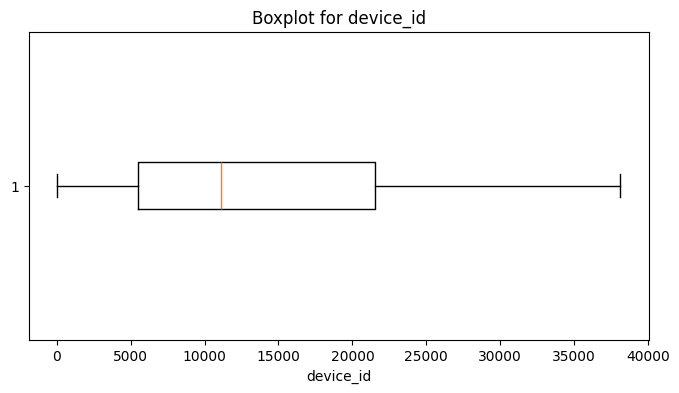

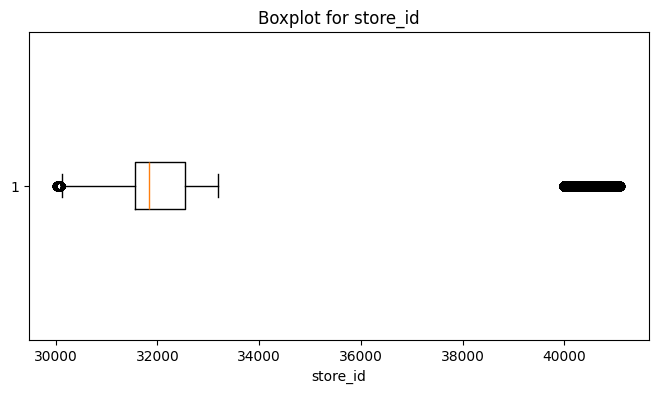

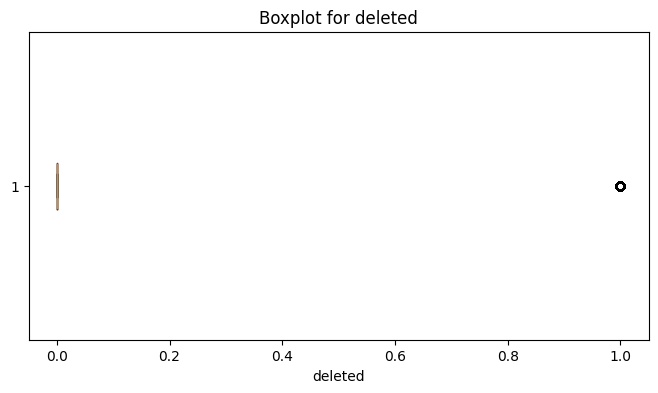

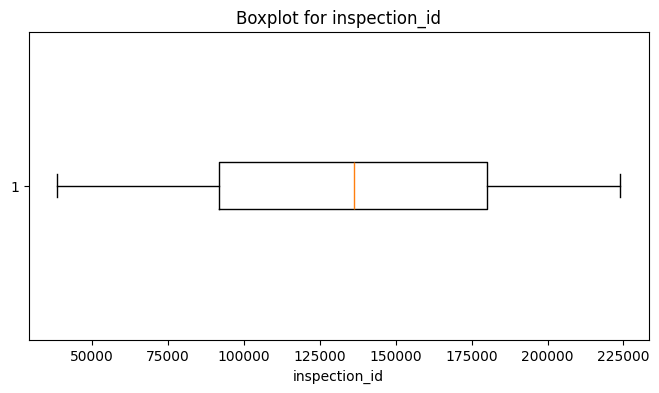

In [ ]:
import matplotlib.pyplot as plt

# Plot boxplots for each numerical column to visualize outliers
for column in combined_data.select_dtypes(include=['float64', 'int64']).columns:
    plt.figure(figsize=(8, 4))
    plt.boxplot(combined_data[column].dropna(), vert=False)  # Drop NA values for visualization
    plt.title(f'Boxplot for {column}')
    plt.xlabel(column)
    plt.show()

Since there are outlier in datasets, so there need to remove. Data that have extreme values could disturb the analysis.

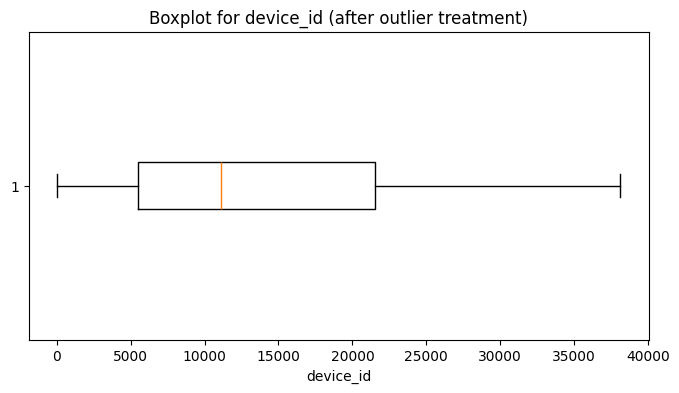

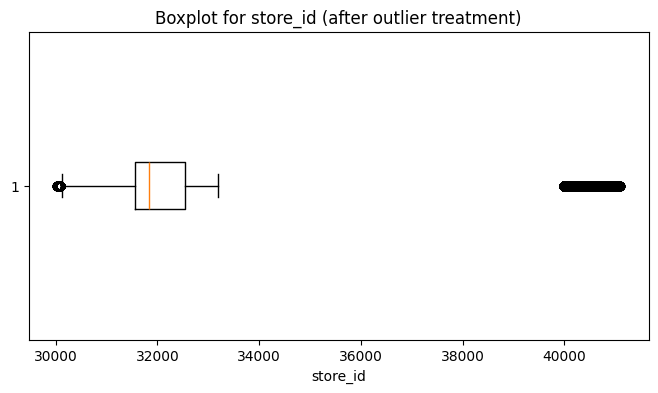

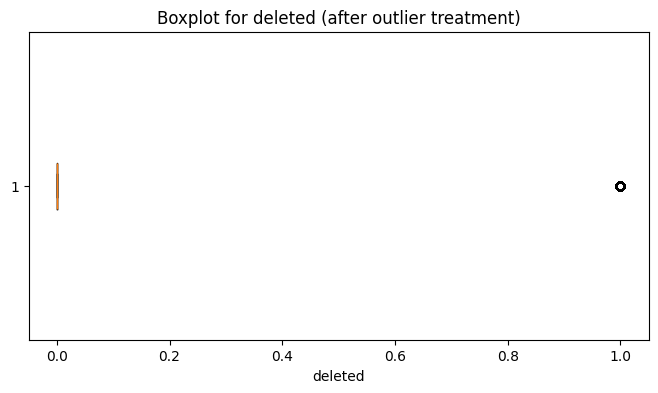

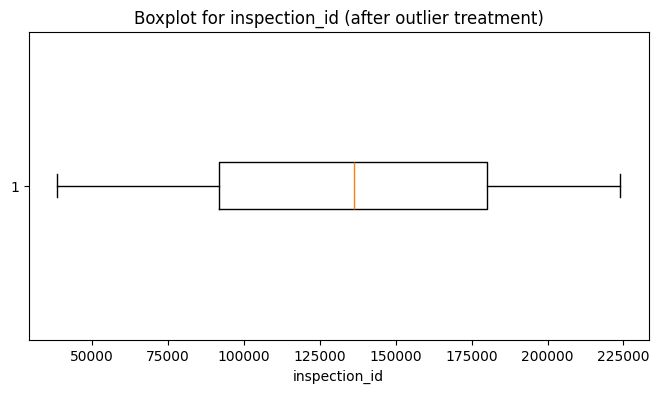

In [ ]:
import pandas as pd

# Loop over each numerical column
for column in combined_data.select_dtypes(include=['float64', 'int64']).columns:
    Q1 = combined_data[column].quantile(0.25)  # 25th percentile
    Q3 = combined_data[column].quantile(0.75)  # 75th percentile
    IQR = Q3 - Q1  # Interquartile range

    # Define the bounds for outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Option 1: Remove outliers
    data = combined_data[(combined_data[column] >= lower_bound) & (combined_data[column] <= upper_bound)]

# Plot the boxplots again after outlier treatment to verify
for column in data.select_dtypes(include=['float64', 'int64']).columns:
    plt.figure(figsize=(8, 4))
    plt.boxplot(data[column].dropna(), vert=False)  # Drop NA values for visualization
    plt.title(f'Boxplot for {column} (after outlier treatment)')
    plt.xlabel(column)
    plt.show()

Outlier will be reduce using Interquartile Range (IQR) and there are still outlier because IQR only remove the extreme outlier to make sure accuracy.


**Breakdown date**

In [ ]:
# Convert 'date' to datetime format using the correct format or infer_datetime_format
combined_data['date'] = pd.to_datetime(combined_data['date'], infer_datetime_format=True)
# or
# combined_data['date'] = pd.to_datetime(combined_data['date'], format='%Y-%m-%d')

# Extract month and year from 'date'
combined_data['month'] = combined_data['date'].dt.month.astype(int)  # Convert to integer
combined_data['year'] = combined_data['date'].dt.year.astype(int)  # Convert to integer

# Drop the original 'date' column and assign back to combined_data
combined_data.drop(['date'], axis=1, inplace=True)

# Display the first few rows to check the result
combined_data.head()

<ipython-input-91-a54de82f39d3>:2: UserWarning:

The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.



,device_id,store_id,device_type,device_group,make,pump,inspection_cycle,deleted,store_name,state,...,fuel_dispenser,scale,timing,misc_inspection,oob,inspection_id,result,reinspection,month,year
0,1.0,33113.0,GASOLINE,FUEL DISPENSER,GILBARCO,1,12 MONTH,0.0,SHEETZ,PA,...,True,False,False,False,False,61501.0,Pass,No,8,2016
1,1.0,33113.0,GASOLINE,FUEL DISPENSER,GILBARCO,1,12 MONTH,0.0,SHEETZ,PA,...,True,False,False,False,False,70260.0,Pass,No,3,2017
2,1.0,33113.0,GASOLINE,FUEL DISPENSER,GILBARCO,1,12 MONTH,0.0,SHEETZ,PA,...,True,False,False,False,False,95902.0,Pass,No,5,2018
3,1.0,33113.0,GASOLINE,FUEL DISPENSER,GILBARCO,1,12 MONTH,0.0,SHEETZ,PA,...,True,False,False,False,False,119569.0,Pass,No,6,2019
4,1.0,33113.0,GASOLINE,FUEL DISPENSER,GILBARCO,1,12 MONTH,0.0,SHEETZ,PA,...,True,False,False,False,False,141657.0,Pass,No,7,2020


In [ ]:
# Extract the number and convert it to integer
combined_data['inspection_cycle'] = combined_data['inspection_cycle'].str.extract('(\d+)').astype(int)

# Rename the column
combined_data = combined_data.rename(columns={'inspection_cycle': 'inspection_cycle_month'})

# Check the result
combined_data.head()


,device_id,store_id,device_type,device_group,make,pump,inspection_cycle_month,deleted,store_name,state,...,fuel_dispenser,scale,timing,misc_inspection,oob,inspection_id,result,reinspection,month,year
0,1.0,33113.0,GASOLINE,FUEL DISPENSER,GILBARCO,1,12,0.0,SHEETZ,PA,...,True,False,False,False,False,61501.0,Pass,No,8,2016
1,1.0,33113.0,GASOLINE,FUEL DISPENSER,GILBARCO,1,12,0.0,SHEETZ,PA,...,True,False,False,False,False,70260.0,Pass,No,3,2017
2,1.0,33113.0,GASOLINE,FUEL DISPENSER,GILBARCO,1,12,0.0,SHEETZ,PA,...,True,False,False,False,False,95902.0,Pass,No,5,2018
3,1.0,33113.0,GASOLINE,FUEL DISPENSER,GILBARCO,1,12,0.0,SHEETZ,PA,...,True,False,False,False,False,119569.0,Pass,No,6,2019
4,1.0,33113.0,GASOLINE,FUEL DISPENSER,GILBARCO,1,12,0.0,SHEETZ,PA,...,True,False,False,False,False,141657.0,Pass,No,7,2020


In [ ]:
#save to csv cleaned_data
combined_data.to_csv('cleaned_data.csv', index=False)

# **Data analysis**

In [ ]:
combined_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 175192 entries, 0 to 180240
Data columns (total 21 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   device_id               175192 non-null  float64
 1   store_id                175192 non-null  float64
 2   device_type             175192 non-null  object 
 3   device_group            175192 non-null  object 
 4   make                    175192 non-null  object 
 5   pump                    175192 non-null  object 
 6   inspection_cycle_month  175192 non-null  int64  
 7   deleted                 175192 non-null  float64
 8   store_name              175192 non-null  object 
 9   state                   175192 non-null  object 
 10  price_verification      175192 non-null  object 
 11  fuel_dispenser          175192 non-null  object 
 12  scale                   175192 non-null  object 
 13  timing                  175192 non-null  object 
 14  misc_inspection         1

In [ ]:
!pip install ydata-profiling

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 390.9/390.9 kB 25.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.5/296.5 kB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 91.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 686.1/686.1 kB 38.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.8/104.8 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 82.2 MB/s eta 0:00:00
  Created wheel for htmlmin: filename=htmlmin-0.1.12-py3-none-any.whl size=27081 sha256=dbba67338bb7f8b75707947acf7ab3cffacf27f376628ef7148ab57e8ed5c687
  Stored in directory: /root/.cache/pip/wheels/dd/91/29/a79cecb328d01739e64017b6fb9a1ab9d8cb1853098ec5966d
Successfully built htmlmin
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.0
    Uninstalling matplotlib-3.10.0:
      Successfully uninstalled matplotlib-3.10.0


In [ ]:
import ydata_profiling as pp
#Interactive and comprehensive EDA/ data description

# forming ProfileReport and save
# as output.html file
profile = pp.ProfileReport(combined_data)
profile.to_file("ML_group_project.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

/usr/local/lib/python3.10/dist-packages/ydata_profiling/model/pandas/summary_pandas.py:47: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  series = series.fillna(np.nan)
/usr/local/lib/python3.10/dist-packages/ydata_profiling/model/pandas/summary_pandas.py:47: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  series = series.fillna(np.nan)
/usr/local/lib/python3.10/dist-packages/ydata_profiling/model/pandas/summary_pandas.py:47: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call res

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

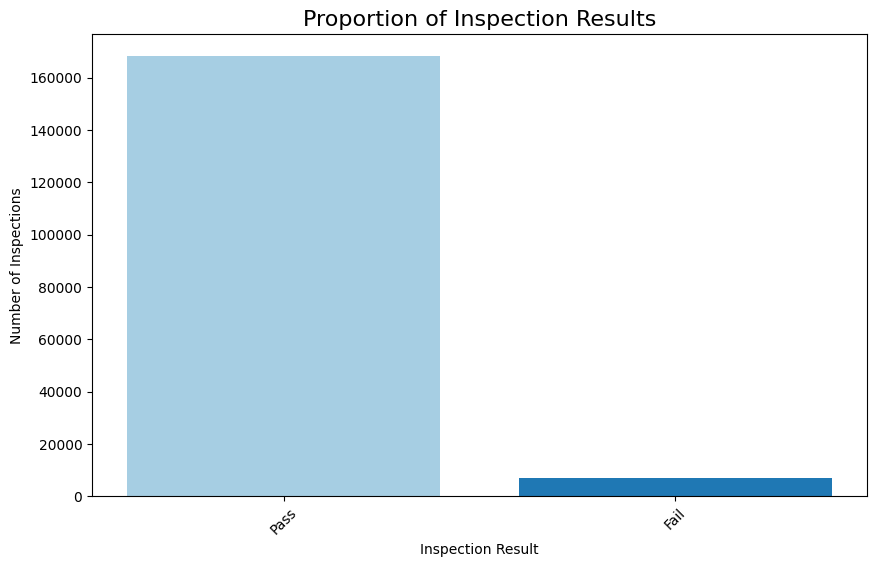

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count the inspection results
result_data = combined_data['result'].value_counts()

# Plot the bar chart for inspection results
plt.figure(figsize=(10, 6))
plt.bar(result_data.index, result_data.values, color=sns.color_palette('Paired'))
plt.title('Proportion of Inspection Results', fontsize=16)
plt.xlabel('Inspection Result')
plt.ylabel('Number of Inspections')
plt.xticks(rotation=45)
plt.show()


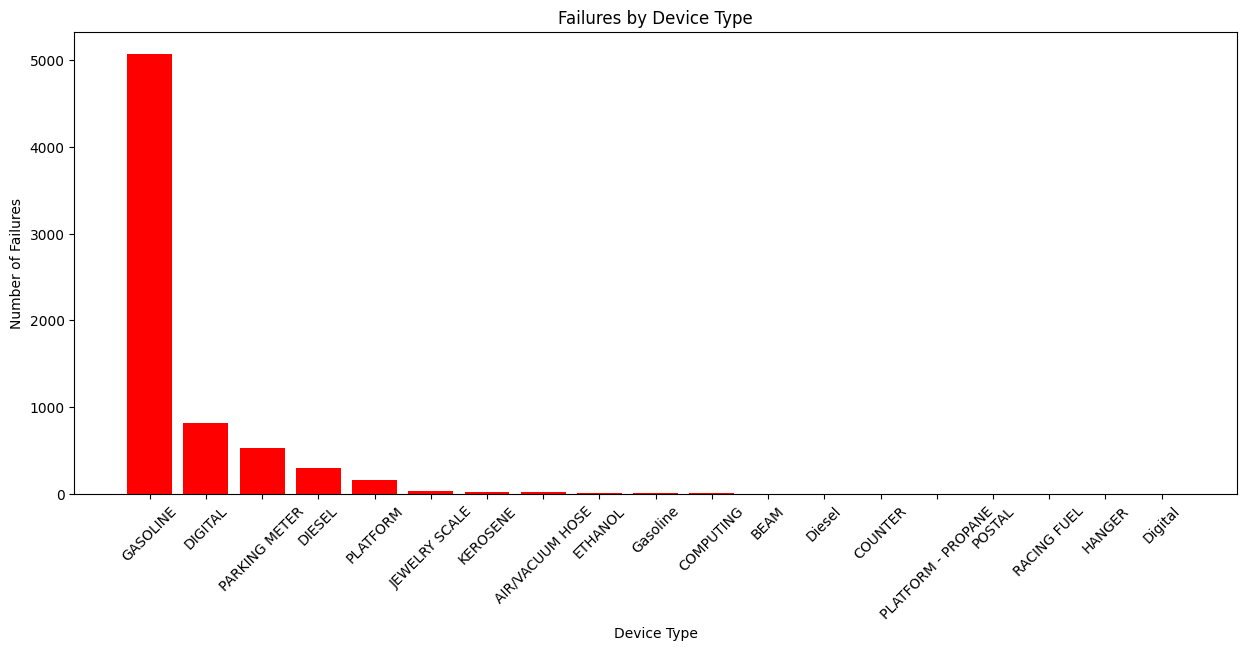

In [ ]:
import matplotlib.pyplot as plt

# Filter for failed inspections
failed_inspections = combined_data[combined_data['result'] == 'Fail']

# Group by device_type and count the failures
failures_by_device_type = failed_inspections.groupby('device_type').size().reset_index(name='failure_count')

# Sort by the number of failures in descending order
failures_by_device_type = failures_by_device_type.sort_values(by='failure_count', ascending=False)

# Plot the failures by device type
plt.figure(figsize=(15, 6))
plt.bar(failures_by_device_type['device_type'], failures_by_device_type['failure_count'], color='red')
plt.title('Failures by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Number of Failures')
plt.xticks(rotation=45)
plt.show()


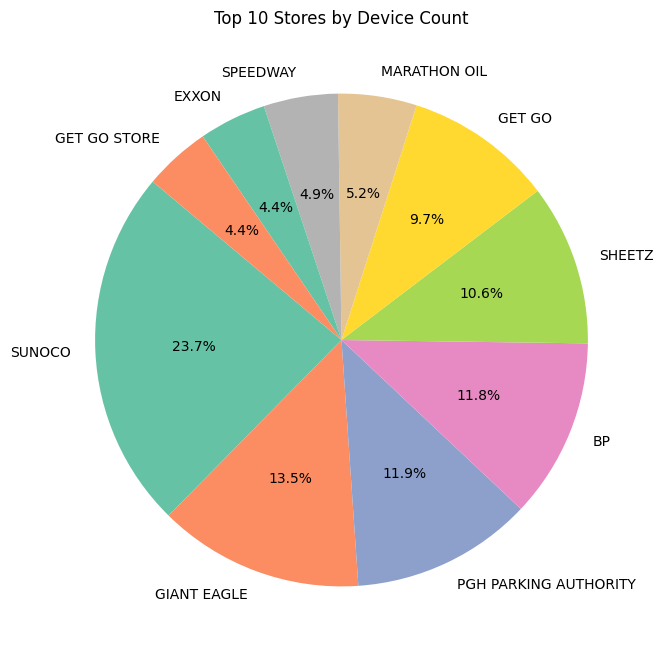

In [ ]:
top_stores = data['store_name'].value_counts().head(10)

# Plot the pie chart
plt.figure(figsize=(8, 8))
plt.pie(top_stores.values, labels=top_stores.index, autopct='%1.1f%%', startangle=140,
        colors=sns.color_palette('Set2'))
plt.title('Top 10 Stores by Device Count')
plt.show()

#**label encoding or one hot encoding**

In [ ]:
lab = LabelEncoder()
# Get categorical columns directly from combined_data
categorical_columns = combined_data.select_dtypes(include=['object']).columns

for col in categorical_columns:
    combined_data[col] = lab.fit_transform(combined_data[col])

In [ ]:
combined_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 175192 entries, 0 to 180240
Data columns (total 21 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   device_id               175192 non-null  float64
 1   store_id                175192 non-null  float64
 2   device_type             175192 non-null  int64  
 3   device_group            175192 non-null  int64  
 4   make                    175192 non-null  int64  
 5   pump                    175192 non-null  int64  
 6   inspection_cycle_month  175192 non-null  int64  
 7   deleted                 175192 non-null  float64
 8   store_name              175192 non-null  int64  
 9   state                   175192 non-null  int64  
 10  price_verification      175192 non-null  int64  
 11  fuel_dispenser          175192 non-null  int64  
 12  scale                   175192 non-null  int64  
 13  timing                  175192 non-null  int64  
 14  misc_inspection         1

#**Feature Selection**

In [ ]:
# Define the target variable (replace 'target_column' with the actual column name)
target_column = 'result'  # Example target column

# Separate features into numerical and categorical
numerical_features = ['device_id', 'store_id', 'inspection_cycle_month', 'inspection_id', 'month', 'year']

# Create the numerical_data DataFrame
numerical_data = combined_data[numerical_features]

# Apply ANOVA (F-Test) for numerical features
anova_f_values, anova_p_values = f_classif(numerical_data, combined_data[target_column])
anova_results = pd.DataFrame({
    'Feature': numerical_features,
    'F-Value': anova_f_values,
    'P-Value': anova_p_values
})

print("ANOVA Results for Numerical Features:")
print(anova_results)

ANOVA Results for Numerical Features:
                  Feature     F-Value       P-Value
0               device_id  356.436903  2.016137e-79
1                store_id  186.340599  2.103166e-42
2  inspection_cycle_month  293.349209  1.048198e-65
3           inspection_id   66.551434  3.431075e-16
4                   month   48.066771  4.133652e-12
5                    year   61.151452  5.314069e-15


The ANOVA test was used to assess the relationship between inspection result and numerical features. Since all the p-value is less than significance value =0.05, then all the features give significance change. Then, i will use all this features to futher analysis.

In [ ]:
target_column = 'result'  # Example target column

categorical_features = [
    'device_type', 'device_group', 'make', 'pump', 'deleted', 'store_name', 'state',
    'price_verification', 'fuel_dispenser', 'scale', 'timing', 'misc_inspection', 'oob',
    'reinspection']

# Apply Chi-Squared Test for categorical features
categorical_data = data[categorical_features]
categorical_data_encoded = categorical_data.apply(LabelEncoder().fit_transform)
chi2_values, chi2_p_values = chi2(categorical_data_encoded, data[target_column]) # changed target to data[target_column]
chi2_results = pd.DataFrame({
    'Feature': categorical_features,
    'Chi2-Value': chi2_values,
    'P-Value': chi2_p_values
})

print("Chi-Squared Test Results for Categorical Features:")
print(chi2_results)

Chi-Squared Test Results for Categorical Features:
               Feature    Chi2-Value        P-Value
0          device_type    477.844540  6.291718e-106
1         device_group   2705.016486   0.000000e+00
2                 make  17937.500432   0.000000e+00
3                 pump  31737.082342   0.000000e+00
4              deleted      3.029792   8.174849e-02
5           store_name   1072.189672  3.659072e-235
6                state           NaN            NaN
7   price_verification      1.517089   2.180605e-01
8       fuel_dispenser    310.017398   2.164884e-69
9                scale    139.541020   3.354155e-32
10              timing     17.238757   3.296425e-05
11     misc_inspection     13.051516   3.030391e-04
12                 oob     31.281713   2.231719e-08
13        reinspection      1.017725   3.130594e-01


- The Chi2 was used to assess the relationship
between inspection result and categorical features.
- Since p-value for deleted, price verification and reinspection greater than significance value =0.05, then this three feautures will be drop because not give significance change.
- except deleted, price verification and reinspection , all features have p-value are less than significance value =0.05, then all the features give significance change. Then, i will use all this features to futher analysis.

- Since the state feature only has a single unique value, the Chi-Squared test cannot compute variability, as there is no variation to test for independence. As a result, the test might return a NaN for both the Chi-Squared value and the p-value. Thus, state will be droped.


In [ ]:
data = combined_data.drop(['deleted', 'price_verification', 'reinspection', 'state', 'device_id', 'store_id', 'inspection_id'], axis=1)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 175192 entries, 0 to 180240
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   device_type             175192 non-null  int64
 1   device_group            175192 non-null  int64
 2   make                    175192 non-null  int64
 3   pump                    175192 non-null  int64
 4   inspection_cycle_month  175192 non-null  int64
 5   store_name              175192 non-null  int64
 6   fuel_dispenser          175192 non-null  int64
 7   scale                   175192 non-null  int64
 8   timing                  175192 non-null  int64
 9   misc_inspection         175192 non-null  int64
 10  oob                     175192 non-null  int64
 11  result                  175192 non-null  int64
 12  month                   175192 non-null  int64
 13  year                    175192 non-null  int64
dtypes: int64(14)
memory usage: 24.1 MB


# **assign target and features**

In [ ]:
X = data.drop(columns=['result'])
y = data['result']

#**data partion**

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2, random_state=42)

# **check imbalance dataset**

In [ ]:
print(data['result'].value_counts())

result
1    168172
0      7020
Name: count, dtype: int64


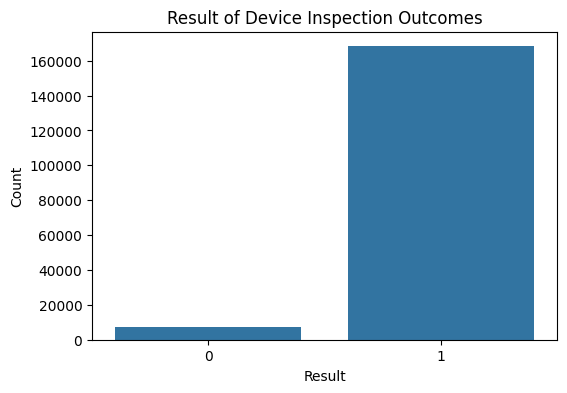

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(x='result', data=data)
plt.title('Result of Device Inspection Outcomes')
plt.xlabel('Result')
plt.ylabel('Count')
plt.show()

The distribution of inspection result shows a clear class imbalance with Class 1 has the most count (164490) while Class 0 has the fewest (6824). This imbalance could lead to a model that favors predicting Class 1 over others that will impact accuracy for less-represented classes.

**overcome imbalance using SMOTE**

In [ ]:
from imblearn.over_sampling import SMOTE

# Convert categorical features in X to numeric
X_encoded = X.apply(LabelEncoder().fit_transform)

# Apply SMOTE
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_encoded, y)

# Check the new target distribution
y_resampled.value_counts()


,count
result,
1,168172
0,168172


In [ ]:
#random over sampling
from imblearn.over_sampling import RandomOverSampler
ros = RandomOverSampler(random_state=42)
X_resampled, y_resampled = ros.fit_resample(X, y)
y_resampled.value_counts()

,count
result,
1,168172
0,168172


#**scalling**

In [ ]:
#scalling
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

we choose standard scalling because to ensures that features with larger values don’t dominate the model, so each feature contributes equally.


#**dimensionality reduction**

In [ ]:
combined_data.shape

(175192, 21)

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)


# **MODEL DEVELOPMENT**

1.ANN-mai

2.kNN-syahir

3.decision tree-faiz

4.random forest-mimi

5 boosting model- .XGBoost


## **1. ANN**

In [ ]:
#ANN
# Define the model architecture
ann = tf.keras.Sequential()
ann.add(tf.keras.layers.Dense(units=34, activation='relu', input_shape=(X_train.shape[1],)))
ann.add(tf.keras.layers.Dense(units=17, activation='relu'))
ann.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

# Compile the model
# Use binary_crossentropy for binary classification and add accuracy metric
ann.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
history = ann.fit(X_train, y_train, batch_size=32, epochs=100, validation_split=0.2)

# Evaluate the model
test_loss, test_accuracy = ann.evaluate(X_test, y_test, verbose=0)
train_loss, train_accuracy = ann.evaluate(X_train, y_train, verbose=0)

print('Model test accuracy: %.3f, ' %test_accuracy,
      'Model training accuracy: %.3f' %train_accuracy)

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



Epoch 1/100
3504/3504 ━━━━━━━━━━━━━━━━━━━━ 17s 4ms/step - accuracy: 0.9605 - loss: 0.1865 - val_accuracy: 0.9593 - val_loss: 0.1669
Epoch 2/100
3504/3504 ━━━━━━━━━━━━━━━━━━━━ 20s 4ms/step - accuracy: 0.9613 - loss: 0.1617 - val_accuracy: 0.9593 - val_loss: 0.1672
Epoch 3/100
3504/3504 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.9600 - loss: 0.1652 - val_accuracy: 0.9593 - val_loss: 0.1668
Epoch 4/100
3504/3504 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9597 - loss: 0.1662 - val_accuracy: 0.9593 - val_loss: 0.1667
Epoch 5/100
3504/3504 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.9613 - loss: 0.1608 - val_accuracy: 0.9593 - val_loss: 0.1690
Epoch 6/100
3504/3504 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9608 - loss: 0.1623 - val_accuracy: 0.9593 - val_loss: 0.1665
Epoch 7/100
3504/3504 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.9602 - loss: 0.1645 - val_accuracy: 0.9593 - val_loss: 0.1667
Epoch 8/100
3504/3504 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.9606 - loss:

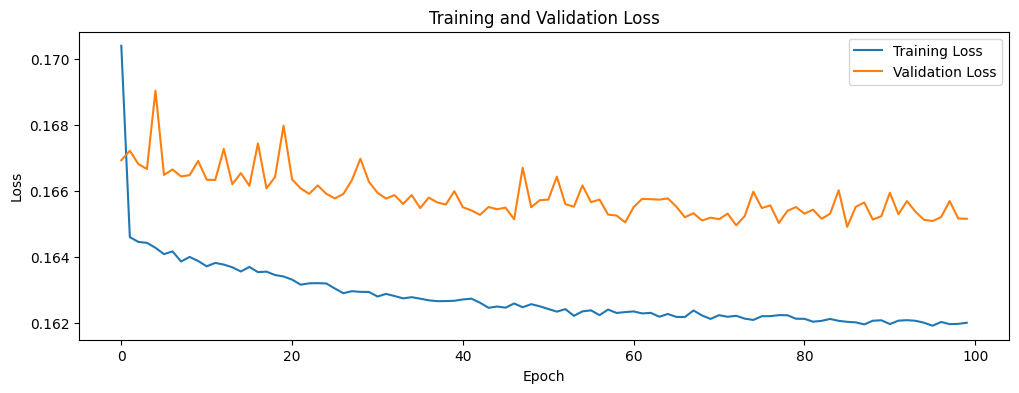

In [ ]:
# Save training and validation loss history
train_loss = history.history['loss']
val_loss = history.history['val_loss']

# Plot training and validation loss over epochs
plt.figure(figsize=(12, 4))
plt.plot(train_loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

Model Performance: The model seems to generalize reasonably well, as the validation loss does not increase significantly (overfitting is minimal).
Loss Gap: A small gap between training and validation loss is expected. However, if this gap were larger, it would indicate overfitting.
Convergence: The model’s training process has converged (loss is no longer significantly decreasing) by around epoch 50-60.

In [ ]:
# Generate predictions
ann_pred= ann.predict(X_test)
ann_pred_binary = (ann_pred > 0.5).astype(int)


1095/1095 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


## **2. kNN**

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

print('Model test Score: %.3f, ' % knn.score(X_test, y_test),
      'Model training Score: %.3f' % knn.score(X_train, y_train))


Model test Score: 0.955,  Model training Score: 0.963


## **3. decision tree**

In [ ]:
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

print('Model test Score: %.3f, ' %dt.score(X_test, y_test),
      'Model training Score: %.3f' %dt.score(X_train, y_train))

Model test Score: 0.952,  Model training Score: 0.972


## **4. boosting model- XGBoost**

In [ ]:
from xgboost import XGBClassifier

# Initialize XGBClassifier without use_label_encoder
xgb = XGBClassifier(eval_metric='logloss', random_state=42)

# Fit the model
xgb.fit(X_train, y_train)

# Make predictions
xgb_pred = xgb.predict(X_test)

 # Model scores on test and training data
print('Model test Score: %.3f, ' %xgb.score(X_test, y_test),
      'Model training Score: %.3f' %xgb.score(X_train, y_train))



Model test Score: 0.960,  Model training Score: 0.960


#**Hyperparameter tuning with Grid Search**

##**1) Decision tree**

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
       'criterion': ['gini', 'entropy'],
       'max_depth': [None, 5, 10, 15, 20],
       'min_samples_split': [2, 5, 10],
       'min_samples_leaf': [1, 2, 4]
             }

grid_search_dt= GridSearchCV(estimator=dt,
                              param_grid=param_grid,
                              cv=10,  # Number of cross-validation folds- lagi banyak kfold lagi lama train
                              scoring='accuracy',  # Evaluation metric
                              verbose=1)

# Fit the model to the training data
grid_search_dt.fit(X_train, y_train) # This line is added to fit the model

## Model scores on test and training data
print('Model test Score: %.3f, ' %grid_search_dt.score(X_test, y_test),
      'Model training Score: %.3f' %grid_search_dt.score(X_train, y_train))

grid_search_dt.fit(X_train, y_train)
best_params = grid_search_dt.best_params_
best_dt_model = grid_search_dt.best_estimator_
print(f"Best parameters: {best_params}")

Fitting 10 folds for each of 90 candidates, totalling 900 fits
Model test Score: 0.960,  Model training Score: 0.960
Fitting 10 folds for each of 90 candidates, totalling 900 fits
Best parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}


In [ ]:
dt_updated = DecisionTreeClassifier(criterion = 'entropy', max_depth= 5, min_samples_leaf = 1, min_samples_split = 2, random_state=42)
dt_updated.fit(X_train, y_train)
dt_pred_updated = dt_updated.predict(X_test)

print('Model test Score: %.3f, ' % dt_updated.score(X_test, y_test),
      'Model training Score: %.3f' % dt_updated.score(X_train, y_train))

Model test Score: 0.960,  Model training Score: 0.960


Random Forest

##**2) knn**

In [ ]:
#knn using gridsearchCV
k_range = list(range(1, 40))# max 40 if lebih akan overfit
param_grid = dict(n_neighbors=k_range)
# defining parameter range
grid = GridSearchCV(knn, param_grid, cv=10, scoring='accuracy',
                    return_train_score=False,verbose=1)

# fitting the model for grid search
grid_search_kNN=grid.fit(X_train, y_train)
print(grid_search_kNN.best_params_)

# Model scores on test and training data
print('Model test Score: %.3f, ' %grid_search_kNN.score(X_test, y_test),
      'Model training Score: %.3f' %grid_search_kNN.score(X_train, y_train))

Fitting 10 folds for each of 39 candidates, totalling 390 fits
{'n_neighbors': 30}
Model test Score: 0.959,  Model training Score: 0.960


In [ ]:
knn_updated= KNeighborsClassifier(n_neighbors=30)
knn_updated.fit(X_train, y_train)
knn_pred_updated = knn_updated.predict(X_test)

print('Model test Score: %.3f, ' % knn_updated.score(X_test, y_test),
      'Model training Score: %.3f' % knn_updated.score(X_train, y_train))


Model test Score: 0.959,  Model training Score: 0.960


ANN

**confusion matrix and classification report**

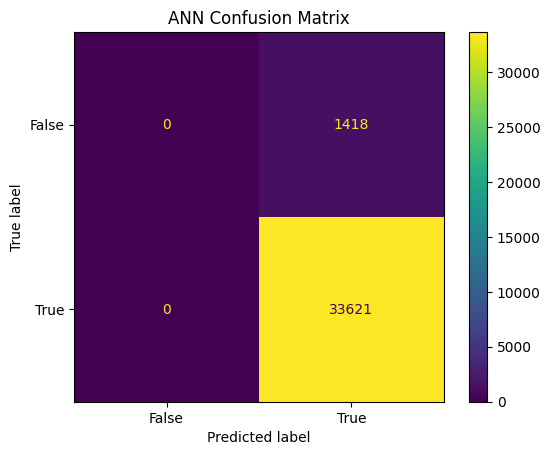

ANN Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00      1418
           1       0.96      1.00      0.98     33621

    accuracy                           0.96     35039
   macro avg       0.48      0.50      0.49     35039
weighted avg       0.92      0.96      0.94     35039



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



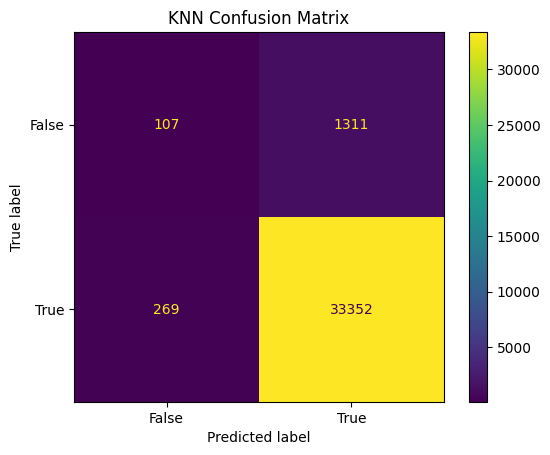

KNN Classification Report:
              precision    recall  f1-score   support

           0       0.28      0.08      0.12      1418
           1       0.96      0.99      0.98     33621

    accuracy                           0.95     35039
   macro avg       0.62      0.53      0.55     35039
weighted avg       0.93      0.95      0.94     35039



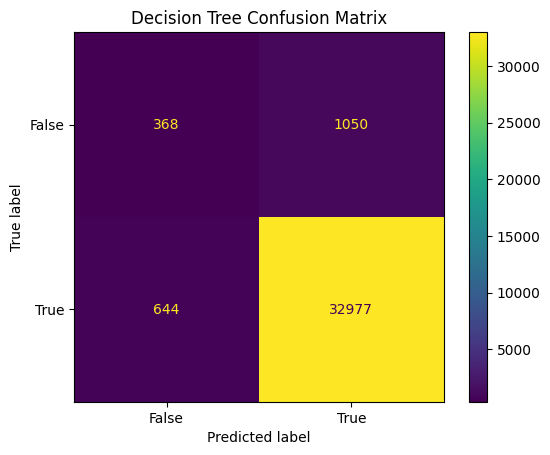

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.36      0.26      0.30      1418
           1       0.97      0.98      0.97     33621

    accuracy                           0.95     35039
   macro avg       0.67      0.62      0.64     35039
weighted avg       0.94      0.95      0.95     35039



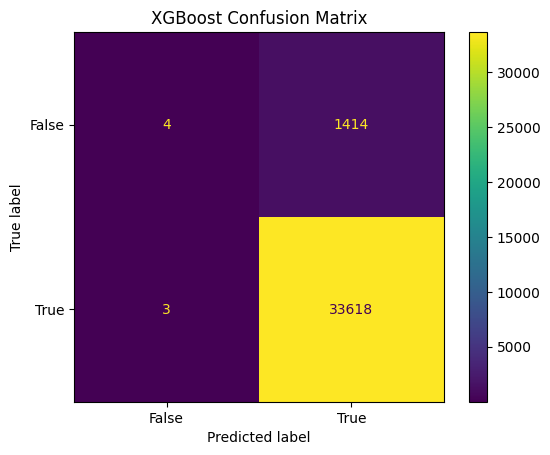

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.00      0.01      1418
           1       0.96      1.00      0.98     33621

    accuracy                           0.96     35039
   macro avg       0.77      0.50      0.49     35039
weighted avg       0.94      0.96      0.94     35039



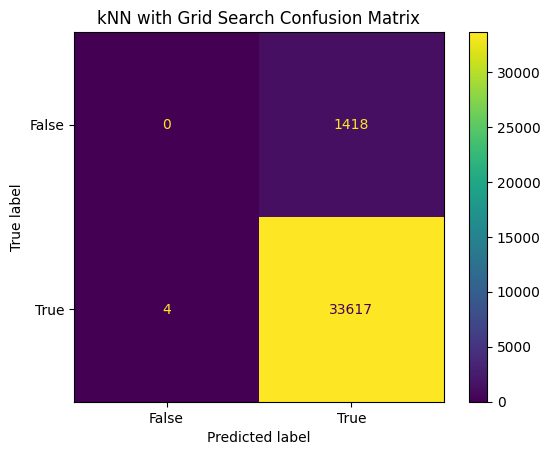

kNN with Grid Search Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00      1418
           1       0.96      1.00      0.98     33621

    accuracy                           0.96     35039
   macro avg       0.48      0.50      0.49     35039
weighted avg       0.92      0.96      0.94     35039



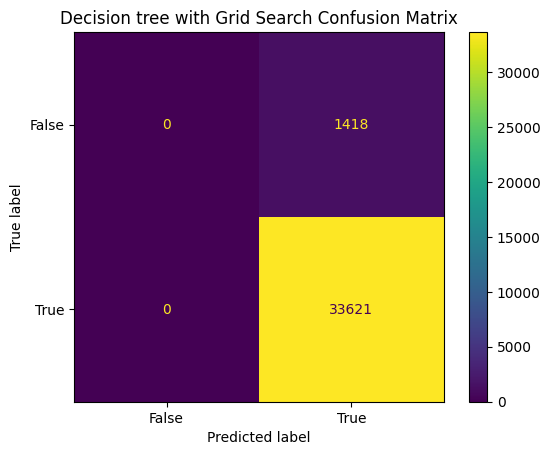

Decision tree with Grid Search Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00      1418
           1       0.96      1.00      0.98     33621

    accuracy                           0.96     35039
   macro avg       0.48      0.50      0.49     35039
weighted avg       0.92      0.96      0.94     35039



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



In [ ]:
from sklearn import metrics
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

# For ANN
confusion_matrix_ann = metrics.confusion_matrix(y_test, (ann_pred > 0.5).astype(int).ravel())  # Convert ann_pred to binary
cm_display_ann = metrics.ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_ann, display_labels=[False, True])
cm_display_ann.plot()
plt.title("ANN Confusion Matrix")
plt.show()
print("ANN Classification Report:")
print(classification_report(y_test, (ann_pred > 0.5).astype(int)))  # Convert ann_pred to binary before passing

# For KNN
confusion_matrix_knn = metrics.confusion_matrix(y_test, knn_pred)
cm_display_knn = metrics.ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_knn, display_labels=[False, True])
cm_display_knn.plot()
plt.title("KNN Confusion Matrix")
plt.show()
print("KNN Classification Report:")
print(classification_report(y_test, knn_pred))

# For Decision Tree
confusion_matrix_dt = metrics.confusion_matrix(y_test, dt_pred)
cm_display_dt = metrics.ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_dt, display_labels=[False, True])
cm_display_dt.plot()
plt.title("Decision Tree Confusion Matrix")
plt.show()
print("Decision Tree Classification Report:")
print(classification_report(y_test, dt_pred))

# For XGBoost
confusion_matrix_xgb = metrics.confusion_matrix(y_test, xgb_pred)
cm_display_xgb = metrics.ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_xgb, display_labels=[False, True])
cm_display_xgb.plot()
plt.title("XGBoost Confusion Matrix")
plt.show()
print("XGBoost Classification Report:")
print(classification_report(y_test, xgb_pred))

# For kNN updated
confusion_matrix_knn_updated = metrics.confusion_matrix(y_test, knn_updated.predict(X_test))
cm_display_knn_updated= metrics.ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_knn_updated, display_labels=[False, True])
cm_display_knn_updated.plot()
plt.title("kNN with Grid Search Confusion Matrix")
plt.show()
print("kNN with Grid Search Classification Report:")
print(classification_report(y_test, knn_updated.predict(X_test))) # Changed here to predict using knn_updated

# For dt updated
confusion_matrix_dt_updated = metrics.confusion_matrix(y_test, dt_updated.predict(X_test))
cm_display_dt_updated= metrics.ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_dt_updated, display_labels=[False, True])
cm_display_dt_updated.plot()
plt.title("Decision tree with Grid Search Confusion Matrix")
plt.show()
print("Decision tree with Grid Search Classification Report:")
print(classification_report(y_test, dt_updated.predict(X_test))) # Changed here to predict using knn_updated



1095/1095 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


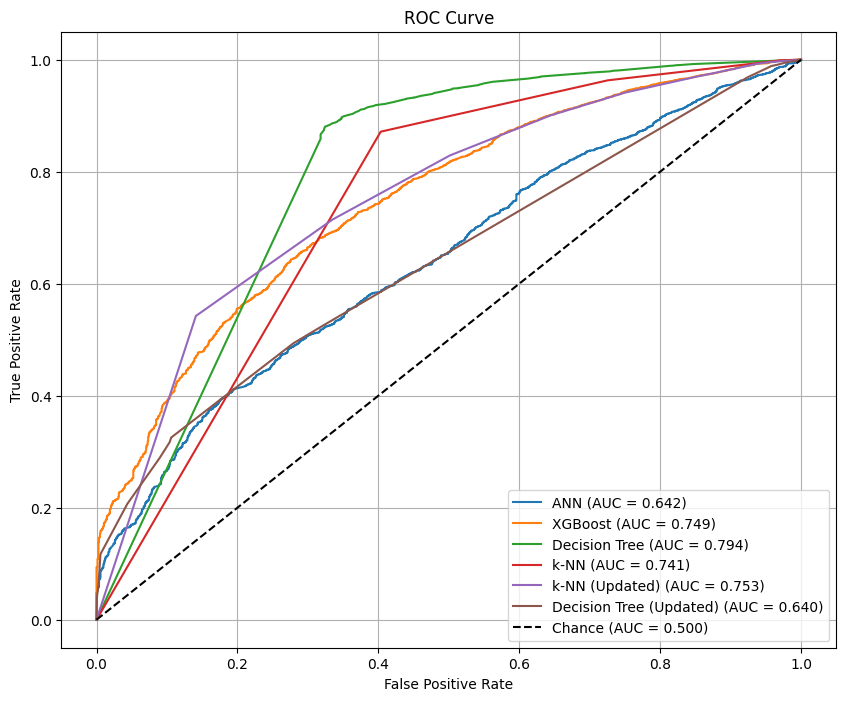

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelBinarizer
import numpy as np

def plot_roc_curve(model_name, y_test, y_pred_prob):
    fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{model_name} (AUC = {roc_auc:.3f})')

if len(np.unique(y_test)) > 2:
    lb = LabelBinarizer()
    y_test_binary = lb.fit_transform(y_test).ravel()
else:
    y_test_binary = y_test

# ANN
ann_pred_prob = ann.predict(X_test).ravel()

# XGBoost
xgb_pred_prob = xgb.predict_proba(X_test)[:, 1]

# Decision Tree
dt_pred_prob = dt.predict_proba(X_test)[:, 1]

# k-NN
knn_pred_prob = knn.predict_proba(X_test)[:, 1]

# k-NN Updated
knn_updated_pred_prob = knn_updated.predict_proba(X_test)[:, 1] # Get probabilities for knn_updated

# Decision Tree Updated
dt_updated_pred_prob = dt_updated.predict_proba(X_test)[:, 1] # Get probabilities for dt_updated


plt.figure(figsize=(10, 8))

# Plot ROC curves for all models
plot_roc_curve('ANN', y_test_binary, ann_pred_prob)
plot_roc_curve('XGBoost', y_test_binary, xgb_pred_prob)
plot_roc_curve('Decision Tree', y_test_binary, dt_pred_prob)
plot_roc_curve('k-NN', y_test_binary, knn_pred_prob)
plot_roc_curve('k-NN (Updated)', y_test_binary, knn_updated_pred_prob)  # Add k-NN (Updated)
plot_roc_curve('Decision Tree (Updated)', y_test_binary, dt_updated_pred_prob)  # Add Decision Tree (Updated)

# Add labels and legend
plt.plot([0, 1], [0, 1], 'k--', label='Chance (AUC = 0.500)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.grid()
plt.show()

In [ ]:

import pandas as pd
from sklearn.metrics import roc_auc_score

# Initialize the list to store results
auc_results = []

# Original models
models = {
    'ANN': ann,
    'XGBoost': xgb,
    'Decision Tree': dt,
    'k-NN': knn,
}

# Add the updated KNN model
models['k-NN (Updated)'] = knn_updated
models['Decision tree (Updated)'] = dt_updated

# Calculate AUC for each model
for model_name, model in models.items():
    if model_name != 'ANN':  # For models other than ANN
        if hasattr(model, "predict_proba"):  # Check if the model supports `predict_proba`
            y_pred_prob = model.predict_proba(X_test)[:, 1]
        else:  # If `predict_proba` is not available, skip
            print(f"Model {model_name} does not support probability prediction.")
            continue
    else:  # For ANN
        y_pred_prob = model.predict(X_test).ravel()

    auc_score = roc_auc_score(y_test_binary, y_pred_prob)
    auc_results.append({'Model': model_name, 'AUC Score': auc_score})

# Create a DataFrame for results
auc_results_df = pd.DataFrame(auc_results)
auc_results_df.sort_values(by='AUC Score', ascending=False, inplace=True)

# Print the AUC results
print("Model With The Highest AUC Score:")
print(auc_results_df)


1095/1095 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Model With The Highest AUC Score:
                     Model  AUC Score
2            Decision Tree   0.793518
4           k-NN (Updated)   0.753132
1                  XGBoost   0.749117
3                     k-NN   0.741082
0                      ANN   0.642215
5  Decision tree (Updated)   0.640423


In [ ]:
mae_rmse_results = []

for model_name, model in models.items():
    if model_name == 'ANN':
        y_pred = model.predict(X_test).ravel()
        y_pred_binary = (y_pred > 0.5).astype(int)  # Convert probabilities to binary predictions
    else:
        y_pred = model.predict(X_test)
        y_pred_binary = y_pred  # For other models, predictions are already binary

    # Calculate MAE and RMSE
    mae = mean_absolute_error(y_test, y_pred_binary)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred_binary))

    mae_rmse_results.append({'Model': model_name, 'MAE': mae, 'RMSE': rmse})

mae_rmse_df = pd.DataFrame(mae_rmse_results)
mae_rmse_df.sort_values(by=['MAE', 'RMSE'], ascending=[True, True], inplace=True)
print("MAE and RMSE Results:")
print(mae_rmse_df)

1095/1095 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
MAE and RMSE Results:
                     Model       MAE      RMSE
1                  XGBoost  0.040441  0.201099
0                      ANN  0.040469  0.201170
5  Decision tree (Updated)  0.040469  0.201170
4           k-NN (Updated)  0.040583  0.201453
3                     k-NN  0.045093  0.212350
2            Decision Tree  0.048346  0.219878


# **Prediction**

In [ ]:
#prediction

predictions = xgb.predict(X_test)
predictions


array([1, 1, 1, ..., 1, 1, 1])

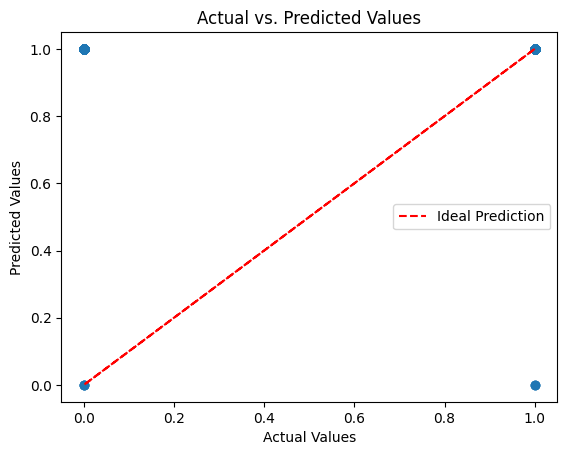

In [ ]:
import matplotlib.pyplot as plt

# Plot yactual vs ypredicted
plt.scatter(y_test, predictions)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs. Predicted Values')

# Add a line for ideal prediction (y = x)
plt.plot(y_test, y_test, color='red', linestyle='--', label='Ideal Prediction')

plt.legend() # Show the legend to identify the line
plt.show()

In [ ]:
import pandas as pd

# Create a DataFrame for the table
data = {'Actual Values': y_test, 'Predicted Values': predictions}
df = pd.DataFrame(data)

# Display the DataFrame as a table
print(df)


        Actual Values  Predicted Values
126091              1                 1
101397              1                 1
105065              1                 1
51540               1                 1
163194              1                 1
...               ...               ...
117693              0                 1
68187               1                 1
155103              1                 1
8364                1                 1
128183              1                 1

[35039 rows x 2 columns]
